<h4>Supervisor Multi-Agent in LangGraph</h4>
This notebook coverts the classic Supervisor Architecture

. <b>Supervisor Agent</b> -- centrally decides which specialized agent should work next

. <b>Researcher Agent</b> -- Searches the web with Tavily

. <b>Chart Generator Agent</b> -- Creates visualizations with Python

. <b> Command --- Lets the supervisor and sub agent dynamically navigate the graph
<h6>

                         ┌──────────────┐
                         │     USER     │
                         └──────┬───────┘
                                │
                                ↓
                         ┌──────────────┐
                         │  SUPERVISOR  │
                         │    AGENT     │
                         └──────┬───────┘
                                │
                                │
                    ┌───────────┴───────────┐
                    │  Command             │
                    │  goto = ...          │
                    │  Dynamic Routing     │
                    └───────────┬───────────┘
                                │
                ┌───────────────┼───────────────┐
                │               │               │
                ↓               ↓               ↓
       ┌────────────────┐ ┌────────────────┐ ┌───────────┐
       │   Researcher   │ │ Chart Generator│ │    END    │
       │     Agent      │ │      Agent     │ │           │
       └───────┬────────┘ └───────┬────────┘ └───────────┘
               │                  │
               │                  │
               ↓                  ↓
       ┌────────────────┐ ┌────────────────┐
       │  Tavily Search │ │  Python Tool   │
       │  Web Research  │ │ Visualization  │
       └───────┬────────┘ └───────┬────────┘
               │                  │
               └──────────┬───────┘
                          │
                          ↓
                   ┌──────────────┐
                   │  SUPERVISOR  │
                   │    AGENT     │
                   └──────┬───────┘
                          │
                          │ Command
                          │ goto = ...
                          ↓
                 ┌────────────────────┐
                 │ Next Agent / END   │
                 └────────────────────┘

</h6>
The key Rule is:

> ** Sub-Agent do not choose sub-agent the supervisor owns the orchestration.**
so the flow is 
Researcher -->  Supervisor --> Chart Agent

2. Enviroment and imports

In [1]:
from typing import Annotated, Sequence, TypedDict
import operator
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_experimental.utilities import PythonREPL
from langgraph.graph import StateGraph
from langgraph.prebuilt import ToolNode
from langgraph.types import Command

In [2]:
load_dotenv()

True

In [3]:
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
TAVILY_API_KEY  = os.getenv("TAVILY_API_KEY")

In [5]:
llm =ChatOpenAI(model="gpt-4o", temperature=0)

<h4>3. Create the Specialist tools</h4>


These are capabilities used inside the specialist agents

1. Tavily- web search

2. Python Repl -- chart generation

                         ┌─────────────────────┐
                         │     SUPERVISOR       │
                         │        AGENT        │
                         └──────────┬──────────┘
                                    │
                    ┌───────────────┴───────────────┐
                    │                               │
                    │                               │
                    ▼                               ▼
          ┌──────────────────┐            ┌──────────────────┐
          │   RESEARCHER     │            │   CHART AGENT    │
          │      AGENT       │            │                  │
          └────────┬─────────┘            └────────┬─────────┘
                   │                               │
                   │                               │
                   ▼                               ▼
             ┌──────────┐                    ┌──────────┐
             │  TAVILY  │                    │  PYTHON  │
             │  SEARCH  │                    │   TOOL   │
             └──────────┘                    └──────────┘
The Supervisor directly routes to the agent. Each agent can have it's own tools

In [22]:
tv_search = TavilySearchResults(
    max_results=5,
    search_depth="advanced",
    max_tokens=100000,
)
repl = PythonREPL()

@tool
def python_repl(code:Annotated[str,"The Python code to execute to generate your chart,"],):
    """Exceute Python code for chart generation"""
    try:
        result = repl.run(code)
    except BaseException as e:
        return f"Failed to execute. Error: {repr(e)}"
    
    return (
        f"Successfully excecuted:\n"
        f"```python\n{code}\n```\n"
        f"Stdout: {result}"
    )

<h4>4.Graph State</h4>

In [21]:
class AgentState(TypedDict):
    messages:Annotated[Sequence[BaseMessage],operator.add]
    sender:str

<h4>5. Researcher Agent</h4>
The Researcher is a specialized sub agent

it is responsibility in only

Search the web and obtain the information needed for the task

when research is completed the Researcher does not call the Chart agent

instead
<h6>
┌──────────────────────┐
│   RESEARCHER AGENT   │
└──────────┬───────────┘
           │
           │ Command(goto="Supervisor")
           │
           ↓
┌──────────────────────┐
│   SUPERVISOR AGENT   │

</h6>
Then Supervisor then decides what should happen next

In [20]:
research_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """You are a Researcher Agent in a Supervised multi-agent system
               your job is to research the user's task using web search tool.
               
               - Search for the required factual information.
               - return useful data and context for the next agent
               - Do not create charts
               - do not decide which other agent should run next.
               
               when your research is complete, return a concise research result.
            """
        ),
        MessagesPlaceholder(variable_name="messages")
    ]
)
research_agent = research_prompt | llm.bind_tools([tv_search])

In [19]:
def researcher_node(state:AgentState):
    result  = research_agent.invoke(state)
    #if the Researcher needs it's own tool, stay inside the Researcher
    if result.tool_calls:
        return Command(
            update= {
                "messages": [result],
                "sender":"researcher_agent",
            },
            goto="research_tools",
        )
    
    #Research is completed , control always returns to the Supervisor
    return Command(
        update={
            "messages":[result],
            "sender":"researcher_agent",
        },
        goto="Supervisor",
    )
  
research_tool_node = ToolNode([tv_search])  

6.Chart generator Agent


it's responsibility is:
    Use the available research/data to generate the requested visualization

it also not decide which specialsed runs next

when it finishes

Chart Agent 
    
    |  Command(goto= "Supervisor)
Supervisor 

In [18]:
chart_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """You are the Chart generator Agent in supervisor multi-agent system.
            
            your job is to create the requested visualization using the python tool.
            
            - Use the research/data available in the conversation.
            - Generate the requested chart.
            - do not perform web search unless explicitly required
            - do not decide which other agent should run next.
            
            When the chart has been successfully generated , return a concise completion message
            """
        ),
        MessagesPlaceholder(variable_name="messages")
    ]
)
chart_agent = chart_prompt | llm.bind_tools([python_repl])

In [23]:
def chart_generator_agent(state:AgentState):
    result  = chart_agent.invoke(state)
    #if the Researcher needs it's own tool, stay inside the Researcher
    if result.tool_calls:
        return Command(
            update= {
                "messages": [result],
                "sender":"chart_generator_agent",
            },
            goto="chart_tools",
        )
    
    #Research is completed , control always returns to the Supervisor
    return Command(
        update={
            "messages":[result],
            "sender":"chart_generator_agent",
        },
        goto="Supervisor",
    )
  
chart_tool_node = ToolNode([python_repl])  

### Define Tool Node

The `ToolNode` executes the tool requested by the current agent.

After the tool finishes, our wrapper uses `Command` to send execution back to
the agent that originally requested the tool.


In [16]:

def research_tools(state):
    #Execute whichever tool the current agent requested.
    result  = research_tool_node.invoke(state) ## tool call and tool param in state
     # sender tells us which agent requested the tool.
    # Command sends execution back to that same agent.
    return Command(
        update={
            "messages": result['messages'],
        },
        goto=state['sender'],
    )

def chart_tools(state):
    #Execute whichever tool the current agent requested.
    result  = chart_tool_node.invoke(state) ## tool call and tool param in state
     # sender tells us which agent requested the tool.
    # Command sends execution back to that same agent.
    return Command(
        update={
            "messages": result['messages'],
        },
        goto=state['sender'],
    )

<h4>Supervisor Agent</h4>

This is the central coordinator

The Supervisor is not given the sub agent as tools

instead the supervisor produces a routing decision into a command

Supervisor LLM
    |
    |decides
Next: researcher
    |
    |
command(goto = "Researcher)

this is the classic Supervisor pattern:

The Supervisor decides which sub agent should execute next



In [24]:
supervisor_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            """you are Supervisor agent coordinating specialized sub-agents.
            
            Available sub agent:
            1. researcher_agent
            - searches the web and obtain factual information
            2. researcher_agent
            - uses available data to create charts and visualization
            
            you are responsible for deciding what should happen next.
            
            Rules:
            - If the user's request requires web reasearch and research has not yet been completed, output:
            NEXT: researcher_agent
            - If research/data is available and a chart is required, output:
            NEXT: chart_generator_agent
            - If the complete user request has been fulfilled, output:
            NEXT: finish
            -Do not perform specialist work yourself.
            -Do not call tools.
            - Do not route directly from one sub-agent to another.
            -Always route through the SUpervisor.
            
            Return exactly one routing decision
            NEXT: researcher_agent
            NEXT: chart_generator_agent
            Next: finish
            
            The conversation history below contains the user request and result from previous agents.
            """
        ),
        MessagesPlaceholder(variable_name="messages")
    ]
)
supervisor_agent = supervisor_prompt | llm

<h4>8. Supervisor Node using Command</h4>

The supervisor LLM decides the next specialist

The Python code translates that decison in to LangGraph Command

Supervisor
    |
    :
    +--- NEXT: researcher
    :          |
    :          +---> Command(goto="Researcher")
    :
    +--- NEXT: chart_generator
    :          |
    :          +---> Command(goto="Chart Generator")
    :
    +--- NEXT: finish
               |
               +---> Command(goto="__end__")

Supervisor is not calling the tool

It's navigating directly to the sub agent node

In [25]:
def supervisor_node(state:AgentState):
    result = supervisor_agent.invoke(state)
    decision = result.content.strip().lower()
    
    if "next: researcher_agent" in decision:
        return Command(
            update={
                "messages":[result],
                "sender":"Supervisor",
            },
            goto="researcher_agent"
        )
    if "next: chart_generator_agent" in decision:
        return Command(
            update={
                "messages":[result],
                "sender":"Supervisor",
            },
            goto="chart_generator_agent"
        )
    return Command(
        update={
            "messages":[result],
        },
        goto="__end__"
    )
        

<h4>9.Build the supervisor Graph</h4>



In [26]:
workflow = StateGraph(AgentState)
workflow.add_node("Supervisor",supervisor_node)
workflow.add_node("researcher_agent",researcher_node)
workflow.add_node("research_tools",research_tools)
workflow.add_node("chart_generator_agent",chart_generator_agent)
workflow.add_node("chart_tools",chart_tools)
workflow.set_entry_point("Supervisor")
supervisor_graph = workflow.compile()


10.Excecution flow conrol

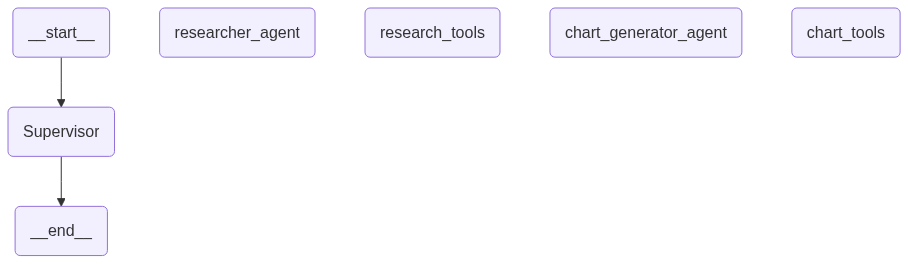

In [27]:
from IPython.display import Image, display, Markdown
display(Image(supervisor_graph.get_graph().draw_mermaid_png()))

Python REPL can execute arbitrary code. Use with caution.


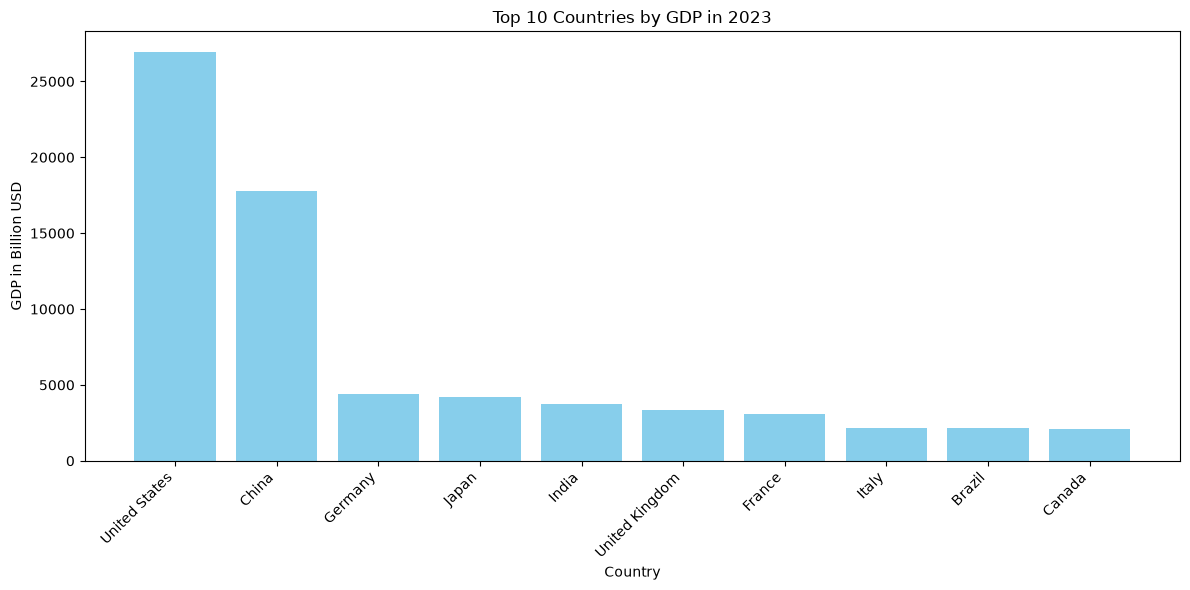

In [28]:
prompt = """Fetch the data of 10 countries with highest GDP in the world.
         Then use this data and draw a bar chart
"""
response = supervisor_graph.invoke({"messages":[('human',prompt)]},
                                   #Maximum number of steps to take in the graph
                                   {"recursion_limit": 150},
                                   )